# Monte Carlo Comparison with Inverse-Covariance Portfolios

A known covariance lets each fitted portfolio be evaluated under the same population risk:

$$
\rho_{b,m}=\frac{\widehat w_{b,m}^{\mathsf T}\Sigma_0\widehat w_{b,m}}{w_0^{\mathsf T}\Sigma_0w_0},
\qquad
E_{b,m}=\left\lVert\widehat w_{b,m}-w_{0,m}\right\rVert_1.
$$

Here, $b$ labels a generated training sample, $m$ labels a portfolio rule, $\widehat w_{b,m}$ is its fitted weight vector, $\Sigma_0$ is the known covariance, $w_0$ is the known minimum-variance portfolio, $\rho_{b,m}$ is the true-risk ratio, $w_{0,m}$ is method $m$ applied to population inputs, and $E_{b,m}$ is allocation error relative to that method's own population-input weights.

,Quantity,Value
0,Assets,24
1,Clusters,4
2,Assets per cluster,6
3,Within-cluster correlation,0.60
4,Between-cluster correlation,0.05
5,Training observations,126
6,Repetitions,60
7,Random seed,2103


,Method,Mean true-risk ratio,Median true-risk ratio,Risk-ratio standard deviation,Mean allocation error,Median allocation error,Mean concentration,Mean largest absolute weight
0,Equal weight,1.358979,1.358979,0,0,0,0.041667,0.041667
1,HRP,1.076840,1.073138,0.016027,0.299038,0.307722,0.057763,0.113042
2,Inverse variance,1.062830,1.062314,0.006577,0.092042,0.091807,0.053702,0.096480
3,Minimum variance,1.220975,1.213103,0.080068,1.146945,1.099082,0.209803,0.268066


,Comparison,Mean paired risk-ratio difference,Share with lower HRP risk
0,HRP minus minimum variance,-0.144135,1
1,HRP minus inverse variance,0.014010,0.116667
2,HRP minus equal weight,-0.282140,1


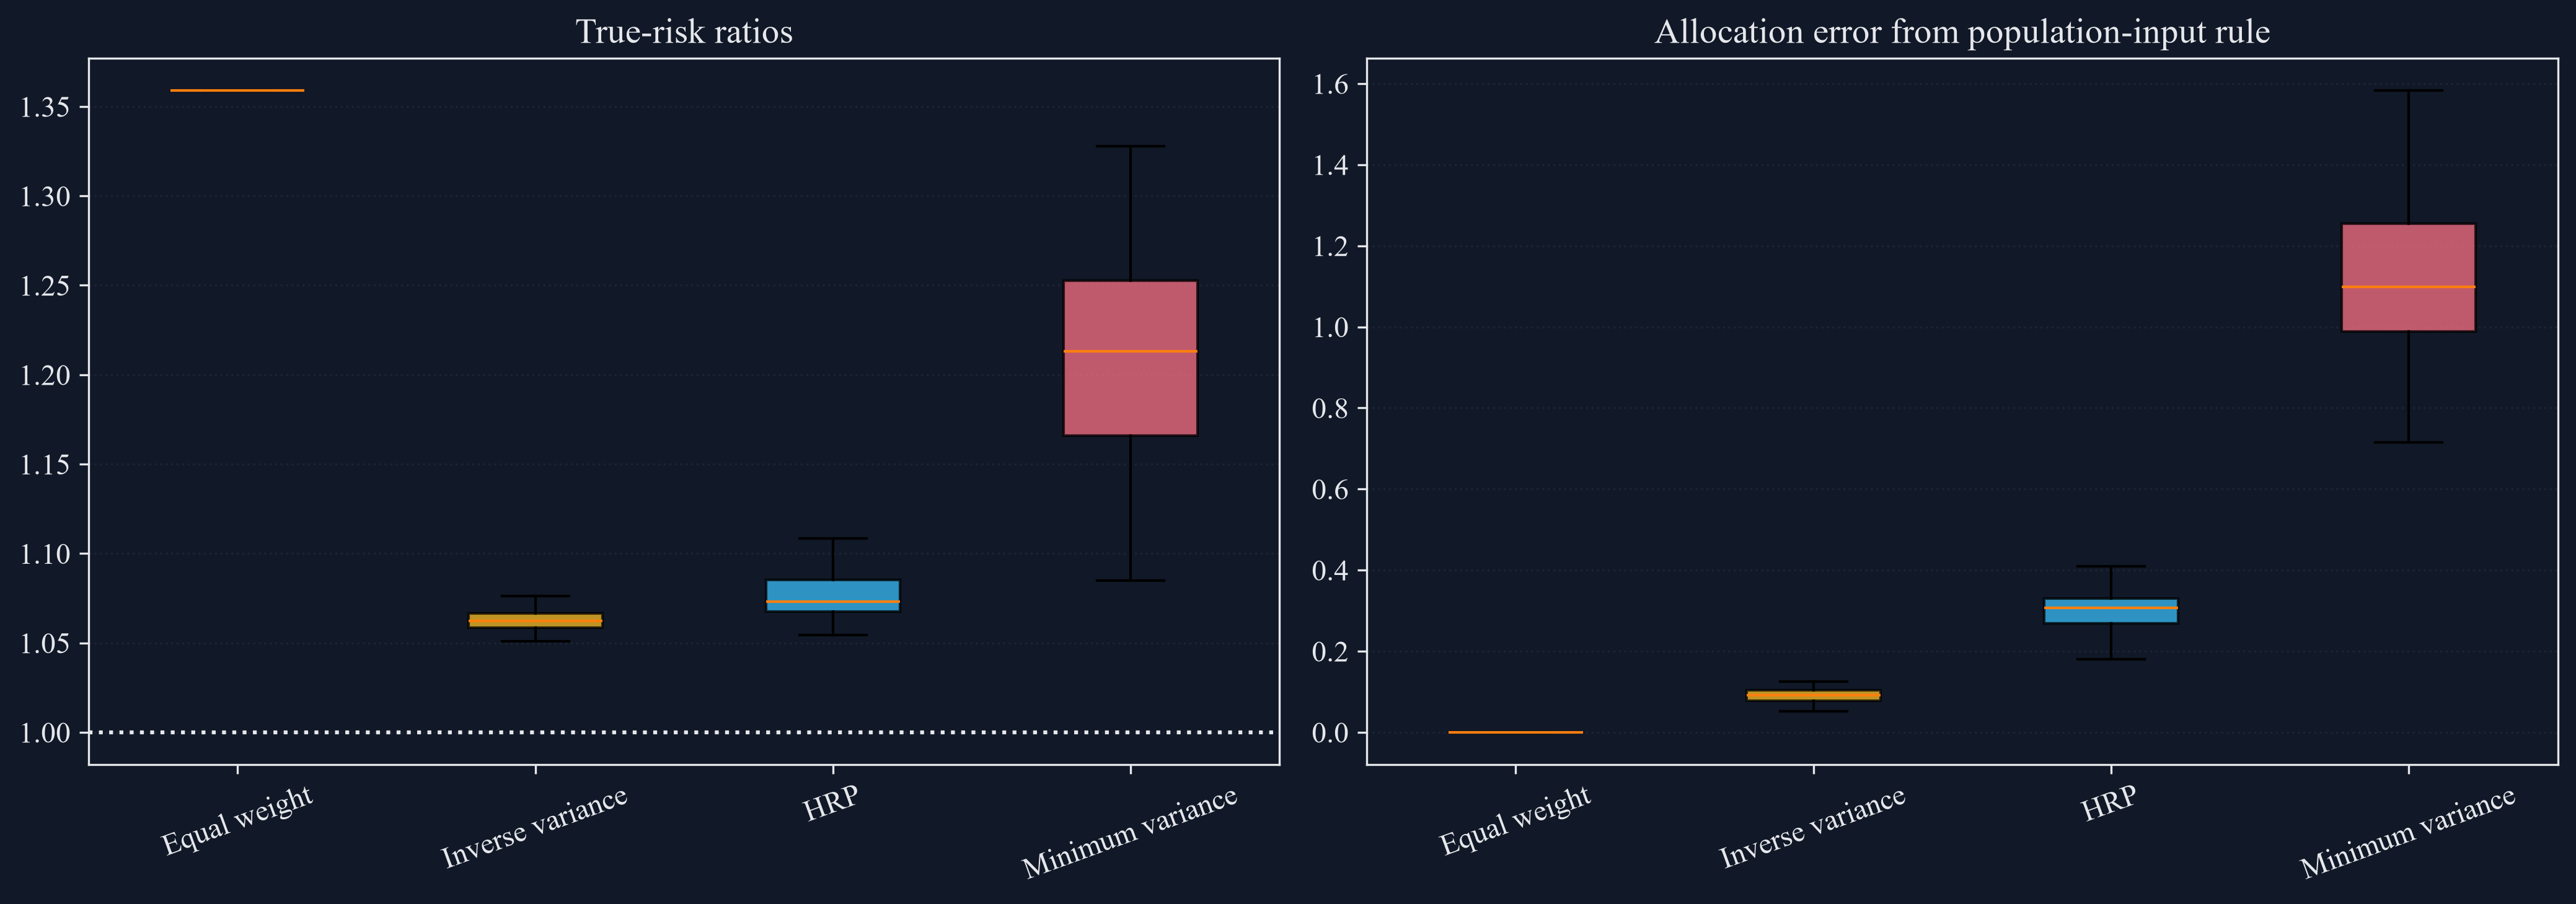

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import sys
import warnings
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform
from sklearn.metrics import adjusted_rand_score
from IPython.display import Image
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import io
import zipfile
DATA_URL = 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip'
DATA_DIR = ROOT / 'data' / 'public' / 'ken_french'
DATA_PATH = ensure_dataset(ROOT, 'french_49_industries')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode('latin1').splitlines()
header_row = next((index for index, line in enumerate(public_lines) if line.startswith(',Agric')))
end_row = next((index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip()))
raw = pd.read_csv(io.StringIO('\n'.join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: 'Date'})
raw['Date'] = pd.to_datetime(raw['Date'].astype(str), format='%Y%m%d')
raw = raw.set_index('Date').replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc['2019-01-01':'2025-12-31'].dropna().copy()
from RiskLabAI.optimization.hrp import cluster_variance, distance_corr, hrp, inverse_variance_weights, quasi_diagonal, recursive_bisection
FIGURES = ROOT / 'outputs' / 'figures' / '25_hierarchical_risk_parity'
TABLES = ROOT / 'outputs' / 'tables' / '25_hierarchical_risk_parity'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151', 'muted': '#94A3B8'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    latex = latex.replace('nan', 'Not available').replace('NaN', 'Not available').replace('inf', 'No finite value')
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')

def save_figure(figure, stem):
    figure.savefig(FIGURES / f'{stem}.png', bbox_inches='tight', dpi=300)
    figure.savefig(FIGURES / f'{stem}.pdf', bbox_inches='tight')
    display(Image(filename=str(FIGURES / f'{stem}.png')))
    plt.close(figure)

def correlation_from_covariance(covariance):
    values = covariance.to_numpy(dtype=float)
    scales = np.sqrt(np.diag(values))
    correlation = values / np.outer(scales, scales)
    correlation = np.clip((correlation + correlation.T) / 2.0, -1.0, 1.0)
    np.fill_diagonal(correlation, 1.0)
    return pd.DataFrame(correlation, index=covariance.index, columns=covariance.columns)

def hierarchy(correlation, method='single'):
    distance = distance_corr(correlation.to_numpy(dtype=float))
    distance = (distance + distance.T) / 2.0
    np.fill_diagonal(distance, 0.0)
    condensed = squareform(distance, checks=True)
    tree = linkage(condensed, method=method)
    order = correlation.index[quasi_diagonal(tree)].tolist()
    return (distance, condensed, tree, order)

def weights_for_method(covariance, correlation, method='single'):
    _, _, tree, order = hierarchy(correlation, method)
    return (recursive_bisection(covariance, order).sort_index(), order, tree)

def global_minimum_variance(covariance):
    values = covariance.to_numpy(dtype=float)
    direction = np.linalg.solve(values, np.ones(values.shape[0]))
    weights = direction / direction.sum()
    return pd.Series(weights, index=covariance.index)

def inverse_variance_series(covariance):
    return pd.Series(inverse_variance_weights(covariance), index=covariance.index)

def portfolio_metrics(name, weights, covariance):
    aligned = weights.reindex(covariance.index).to_numpy(dtype=float)
    variance = float(aligned @ covariance.to_numpy(dtype=float) @ aligned)
    concentration = float(aligned @ aligned)
    return {'Portfolio': name, 'Annual volatility': float(np.sqrt(variance)), 'Largest weight': float(aligned.max()), 'Smallest weight': float(aligned.min()), 'Gross exposure': float(np.abs(aligned).sum()), 'Weight concentration': concentration, 'Effective holdings': float(1.0 / concentration)}

def one_way_turnover(current, previous):
    return float(0.5 * np.abs(current.sort_index().to_numpy() - previous.sort_index().to_numpy()).sum())
selected_assets = list(industry_returns.columns[:16])
public_sample = industry_returns[selected_assets].copy()
annual_covariance = public_sample.cov() * 252.0
public_correlation = public_sample.corr()
data_provenance = pd.DataFrame({'Field': ['Archive', 'Provider', 'Return type', 'Analysis start', 'Analysis end', 'Complete dates', 'Selected industries'], 'Value': ['49_Industry_Portfolios_daily_CSV.zip', 'Kenneth R. French Data Library', 'Daily value-weighted return', str(public_sample.index.min().date()), str(public_sample.index.max().date()), len(public_sample), len(selected_assets)]})

def clustered_covariance(asset_count, cluster_count, within_correlation, between_correlation):
    if asset_count % cluster_count != 0:
        raise ValueError('Asset count must be divisible by cluster count')
    block_size = asset_count // cluster_count
    correlation = np.full((asset_count, asset_count), between_correlation, dtype=float)
    for cluster in range(cluster_count):
        start = cluster * block_size
        end = start + block_size
        correlation[start:end, start:end] = within_correlation
    np.fill_diagonal(correlation, 1.0)
    volatilities = np.linspace(0.12, 0.28, asset_count)
    covariance = correlation * np.outer(volatilities, volatilities)
    names = [f'A{index + 1:02d}' for index in range(asset_count)]
    return (pd.DataFrame(covariance, index=names, columns=names), pd.DataFrame(correlation, index=names, columns=names))

def portfolio_set(covariance, correlation):
    count = len(covariance)
    return {'Equal weight': pd.Series(1.0 / count, index=covariance.index), 'Inverse variance': inverse_variance_series(covariance), 'HRP': hrp(covariance, correlation), 'Minimum variance': global_minimum_variance(covariance)}
true_covariance, true_correlation = clustered_covariance(24, 4, 0.6, 0.05)
population_weights = portfolio_set(true_covariance, true_correlation)
true_minimum_weights = population_weights['Minimum variance']
true_minimum_variance = float(true_minimum_weights @ true_covariance @ true_minimum_weights)
design_table = pd.DataFrame({'Quantity': ['Assets', 'Clusters', 'Assets per cluster', 'Within-cluster correlation', 'Between-cluster correlation', 'Training observations', 'Repetitions', 'Random seed'], 'Value': [24, 4, 6, 0.6, 0.05, 126, 60, 2103]})
save_table(design_table, 'known_truth_design', 'Known clustered covariance design.', 'tab:chapter21-known-truth-design')
display(design_table)
rng = np.random.default_rng(2103)
repeated_rows = []
for repetition in range(60):
    sample = rng.multivariate_normal(np.zeros(len(true_covariance)), true_covariance.to_numpy(), size=126)
    sample_frame = pd.DataFrame(sample, columns=true_covariance.index)
    sample_covariance = sample_frame.cov()
    sample_correlation = sample_frame.corr()
    fitted = portfolio_set(sample_covariance, sample_correlation)
    for method, weights in fitted.items():
        aligned = weights.reindex(true_covariance.index)
        true_variance = float(aligned @ true_covariance @ aligned)
        repeated_rows.append({'Repetition': repetition + 1, 'Method': method, 'True-risk ratio': true_variance / true_minimum_variance, 'Allocation absolute error': float(np.abs(aligned - population_weights[method]).sum()), 'Weight concentration': float(aligned @ aligned), 'Largest absolute weight': float(np.abs(aligned).max())})
repeated_results = pd.DataFrame(repeated_rows)
repeated_summary = repeated_results.groupby('Method', as_index=False).agg(**{'Mean true-risk ratio': ('True-risk ratio', 'mean'), 'Median true-risk ratio': ('True-risk ratio', 'median'), 'Risk-ratio standard deviation': ('True-risk ratio', 'std'), 'Mean allocation error': ('Allocation absolute error', 'mean'), 'Median allocation error': ('Allocation absolute error', 'median'), 'Mean concentration': ('Weight concentration', 'mean'), 'Mean largest absolute weight': ('Largest absolute weight', 'mean')})
risk_pivot = repeated_results.pivot(index='Repetition', columns='Method', values='True-risk ratio')
paired_comparison = pd.DataFrame({'Comparison': ['HRP minus minimum variance', 'HRP minus inverse variance', 'HRP minus equal weight'], 'Mean paired risk-ratio difference': [(risk_pivot['HRP'] - risk_pivot['Minimum variance']).mean(), (risk_pivot['HRP'] - risk_pivot['Inverse variance']).mean(), (risk_pivot['HRP'] - risk_pivot['Equal weight']).mean()], 'Share with lower HRP risk': [(risk_pivot['HRP'] < risk_pivot['Minimum variance']).mean(), (risk_pivot['HRP'] < risk_pivot['Inverse variance']).mean(), (risk_pivot['HRP'] < risk_pivot['Equal weight']).mean()]})
save_table(repeated_summary, 'repeated_known_truth_summary', 'Repeated known-covariance portfolio results.', 'tab:chapter21-repeated-summary')
save_table(paired_comparison, 'repeated_paired_comparison', 'Paired true-risk comparisons with HRP.', 'tab:chapter21-paired-comparison')
display(repeated_summary)
display(paired_comparison)
method_order = ['Equal weight', 'Inverse variance', 'HRP', 'Minimum variance']
colors = [palette['green'], palette['amber'], palette['cyan'], palette['rose']]
figure, axes = plt.subplots(1, 2, figsize=(14, 5))
risk_data = [repeated_results.loc[repeated_results['Method'] == method, 'True-risk ratio'] for method in method_order]
error_data = [repeated_results.loc[repeated_results['Method'] == method, 'Allocation absolute error'] for method in method_order]
risk_box = axes[0].boxplot(risk_data, tick_labels=method_order, patch_artist=True, showfliers=False)
error_box = axes[1].boxplot(error_data, tick_labels=method_order, patch_artist=True, showfliers=False)
for patches in [risk_box['boxes'], error_box['boxes']]:
    for patch, color in zip(patches, colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)
axes[0].set_title('True-risk ratios')
axes[0].axhline(1.0, color=palette['text'], linestyle=':')
axes[1].set_title('Allocation error from population-input rule')
for axis in axes:
    axis.tick_params(axis='x', rotation=20)
    axis.grid(axis='y', alpha=0.3)
figure.tight_layout()
save_figure(figure, 'repeated_known_truth_portfolios')
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Testing when clusters remain stable

The dimension-to-sample ratio records how much covariance information is estimated from each training sample:

$$
q=\frac{N}{T}.
$$

Here, $N$ is the number of assets, $T$ is the number of training observations, and $q$ is larger when the covariance problem has more dimensions relative to the available history.

,Assets,Training observations,Within correlation,Dimension-to-sample ratio,Method,Mean true-risk ratio,Median true-risk ratio,Mean allocation error
0,12,63,0.3,0.190476,HRP,1.060291,1.056931,0.248261
1,12,63,0.3,0.190476,Minimum variance,1.179377,1.164842,0.499181
2,12,63,0.6,0.190476,HRP,1.063998,1.061068,0.318989
3,12,63,0.6,0.190476,Minimum variance,1.218644,1.209720,0.769963
4,12,126,0.3,0.095238,HRP,1.032530,1.028421,0.193802
5,12,126,0.3,0.095238,Minimum variance,1.092641,1.084243,0.355520
6,12,126,0.6,0.095238,HRP,1.056853,1.054110,0.267372
7,12,126,0.6,0.095238,Minimum variance,1.089098,1.085430,0.472750
8,12,252,0.3,0.047619,HRP,1.027525,1.029274,0.169515
9,12,252,0.3,0.047619,Minimum variance,1.051385,1.048351,0.256231


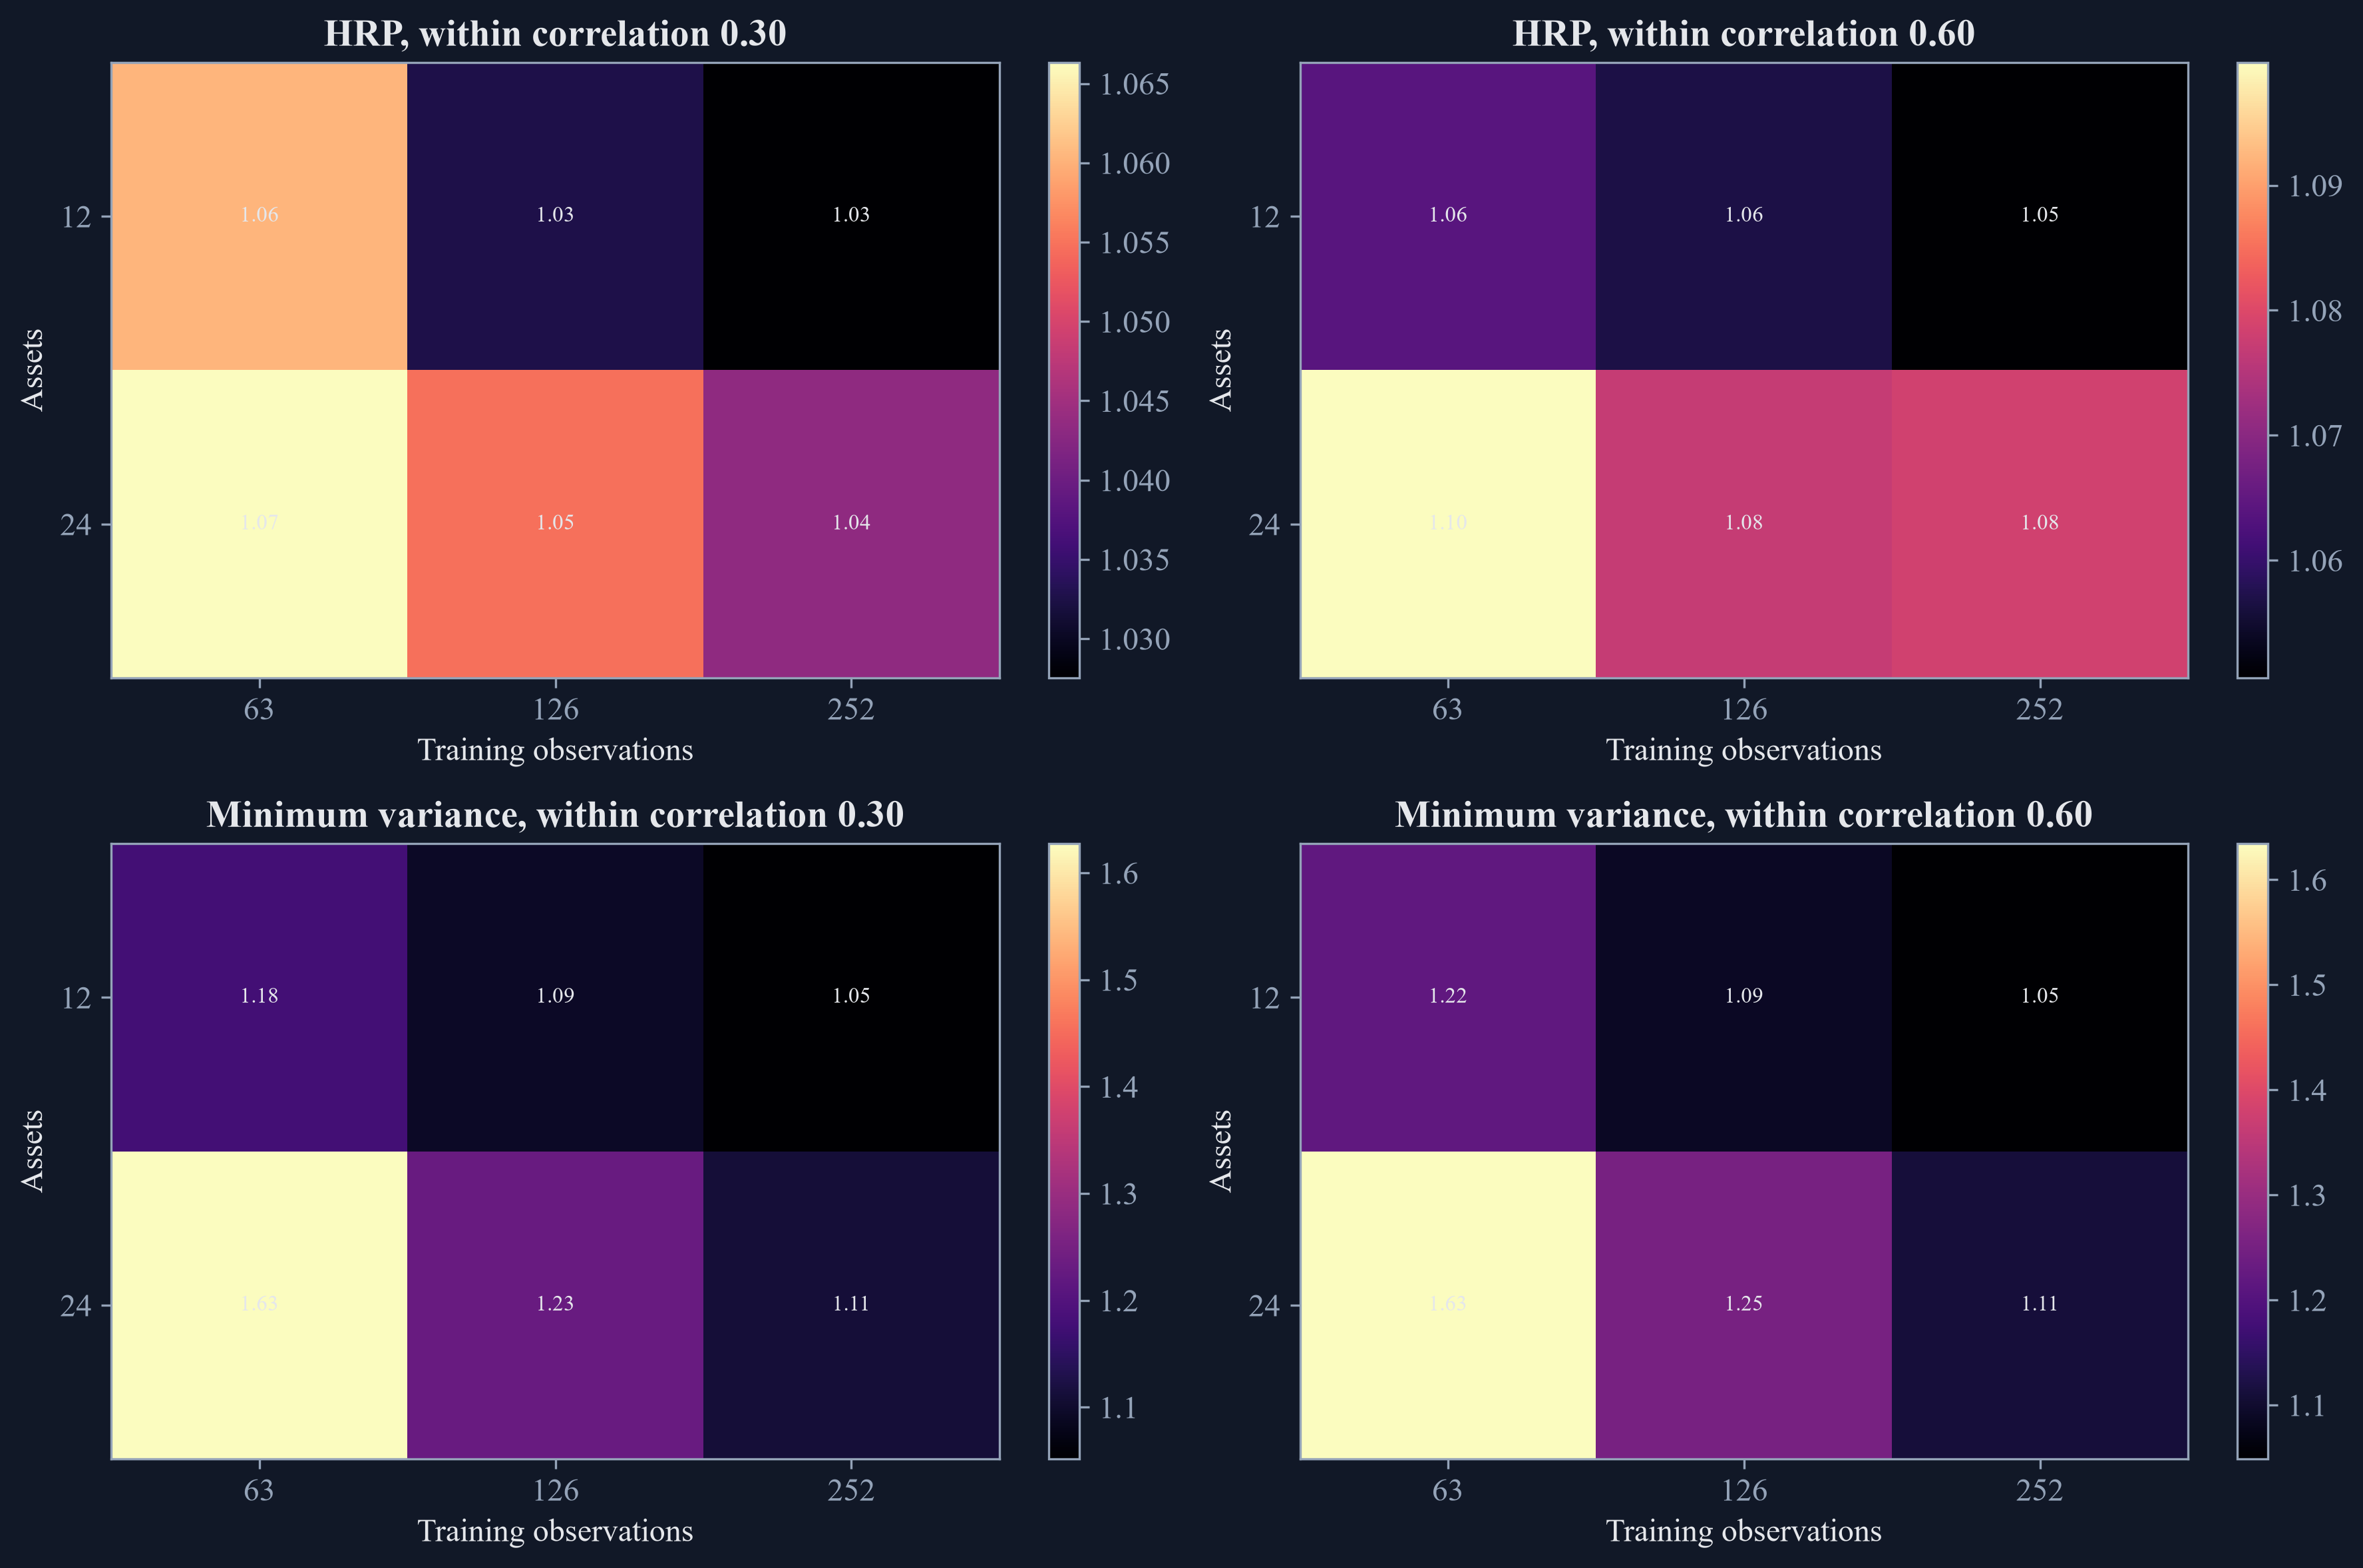

In [2]:
sensitivity_rows = []
sensitivity_rng = np.random.default_rng(2113)
for asset_count in [12, 24]:
    for training_length in [63, 126, 252]:
        for within_correlation in [0.30, 0.60]:
            covariance, correlation = clustered_covariance(asset_count, 4, within_correlation, 0.05)
            oracle = portfolio_set(covariance, correlation)
            minimum = oracle["Minimum variance"]
            minimum_variance = float(minimum @ covariance @ minimum)
            for repetition in range(20):
                sample = sensitivity_rng.multivariate_normal(np.zeros(asset_count), covariance.to_numpy(), size=training_length)
                frame = pd.DataFrame(sample, columns=covariance.index)
                fitted = portfolio_set(frame.cov(), frame.corr())
                for method in ["HRP", "Minimum variance"]:
                    weights = fitted[method]
                    sensitivity_rows.append({"Assets": asset_count, "Training observations": training_length, "Within correlation": within_correlation, "Dimension-to-sample ratio": asset_count / training_length, "Repetition": repetition + 1, "Method": method, "True-risk ratio": float(weights @ covariance @ weights) / minimum_variance, "Allocation absolute error": float(np.abs(weights - oracle[method]).sum())})
sensitivity_results = pd.DataFrame(sensitivity_rows)
sensitivity_summary = sensitivity_results.groupby(["Assets", "Training observations", "Within correlation", "Dimension-to-sample ratio", "Method"], as_index=False).agg(**{"Mean true-risk ratio": ("True-risk ratio", "mean"), "Median true-risk ratio": ("True-risk ratio", "median"), "Mean allocation error": ("Allocation absolute error", "mean")})
save_table(sensitivity_summary, "sampling_sensitivity_summary", "Known-covariance sensitivity to sample size, dimension, and cluster strength.", "tab:chapter21-sampling-sensitivity")
display(sensitivity_summary)

figure, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, method in enumerate(["HRP", "Minimum variance"]):
    for column, within_correlation in enumerate([0.30, 0.60]):
        subset = sensitivity_summary[(sensitivity_summary["Method"] == method) & (sensitivity_summary["Within correlation"] == within_correlation)]
        matrix = subset.pivot(index="Assets", columns="Training observations", values="Mean true-risk ratio").sort_index().sort_index(axis=1)
        image = axes[row, column].imshow(matrix.to_numpy(), cmap="magma", aspect="auto")
        axes[row, column].set_title(f"{method}, within correlation {within_correlation:.2f}")
        axes[row, column].set_xticks(range(len(matrix.columns)))
        axes[row, column].set_xticklabels(matrix.columns)
        axes[row, column].set_yticks(range(len(matrix.index)))
        axes[row, column].set_yticklabels(matrix.index)
        axes[row, column].set_xlabel("Training observations")
        axes[row, column].set_ylabel("Assets")
        for y in range(matrix.shape[0]):
            for x in range(matrix.shape[1]):
                axes[row, column].text(x, y, f"{matrix.iloc[y, x]:.2f}", ha="center", va="center", color=palette["text"], fontsize=8)
        figure.colorbar(image, ax=axes[row, column], fraction=0.046)
figure.tight_layout()
save_figure(figure, "sampling_sensitivity_heatmaps")

## How tree instability creates turnover

One-way turnover measures the fraction of the portfolio that changes between two weight vectors:

$$
\operatorname{TO}_k=\frac{1}{2}\left\lVert w_k-w_{k-1}\right\rVert_1.
$$

Here, $k$ labels an allocation date, $w_k$ and $w_{k-1}$ are consecutive fully invested weight vectors, $\lVert\cdot\rVert_1$ is the sum of absolute changes, and $\operatorname{TO}_k$ excludes trading costs.

,Quantity,Value
0,Allocation dates,12
1,Mean estimated-tree turnover,0.116942
2,Mean fixed-order turnover,0.030774
3,Mean same-covariance topology gap,0.121813
4,Maximum topology gap,0.166307
5,Exact population-order matches,0


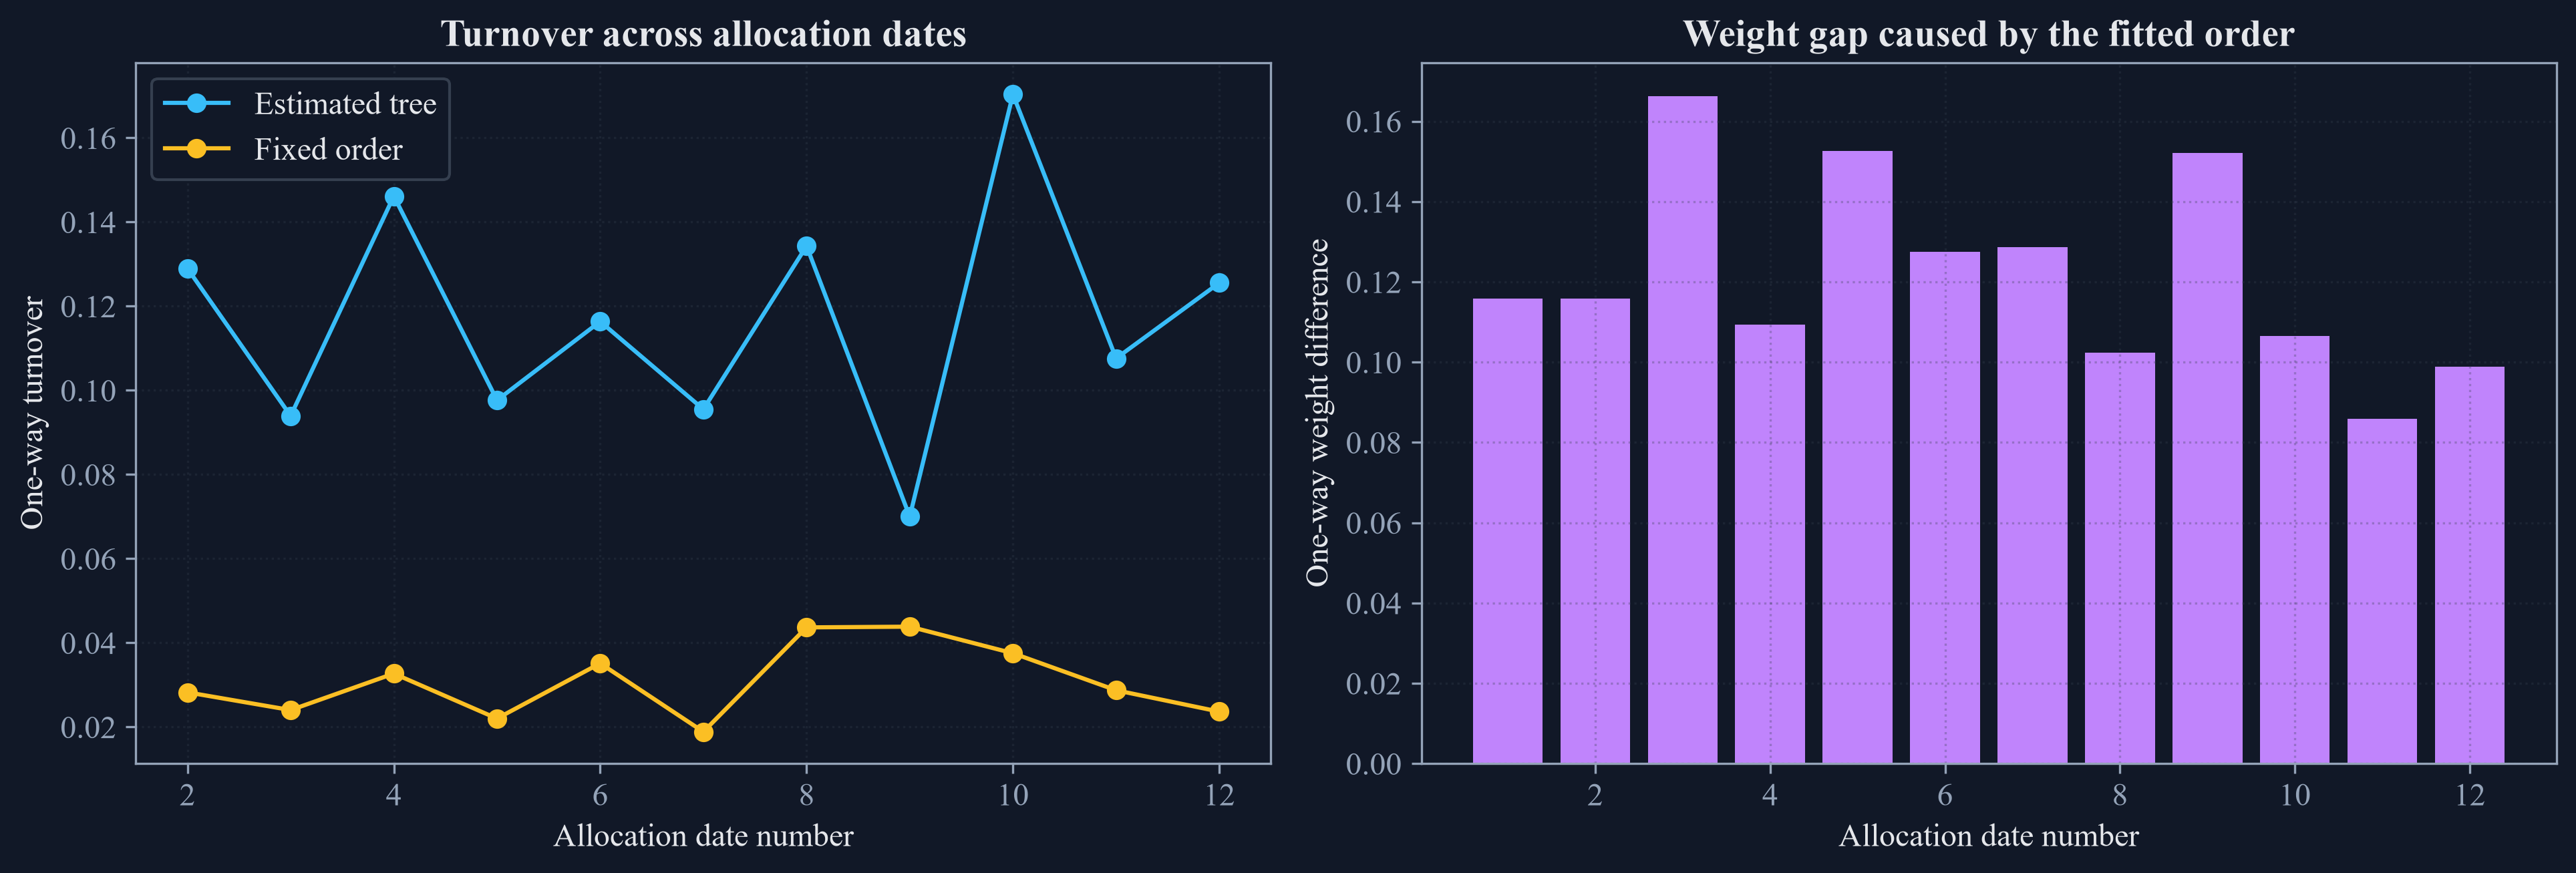

In [3]:
turnover_rng = np.random.default_rng(2123)
turnover_sample = pd.DataFrame(turnover_rng.multivariate_normal(np.zeros(len(true_covariance)), true_covariance.to_numpy(), size=1000), columns=true_covariance.index)
_, _, true_tree, true_order = hierarchy(true_correlation, "single")
topology_rows = []
previous_estimated = None
previous_fixed = None
for fold, endpoint in enumerate(range(251, len(turnover_sample), 63), start=1):
    training = turnover_sample.iloc[endpoint - 251:endpoint + 1]
    covariance = training.cov()
    correlation = training.corr()
    _, _, estimated_tree, estimated_order = hierarchy(correlation, "single")
    estimated_weights = recursive_bisection(covariance, estimated_order).sort_index()
    fixed_weights = recursive_bisection(covariance, true_order).sort_index()
    topology_rows.append({"Fold": fold, "Estimated-tree turnover": np.nan if previous_estimated is None else one_way_turnover(estimated_weights, previous_estimated), "Fixed-order turnover": np.nan if previous_fixed is None else one_way_turnover(fixed_weights, previous_fixed), "Same-covariance topology gap": one_way_turnover(estimated_weights, fixed_weights), "Estimated order equals population order": int(estimated_order == true_order)})
    previous_estimated = estimated_weights
    previous_fixed = fixed_weights
topology_turnover = pd.DataFrame(topology_rows)
topology_summary = pd.DataFrame({"Quantity": ["Allocation dates", "Mean estimated-tree turnover", "Mean fixed-order turnover", "Mean same-covariance topology gap", "Maximum topology gap", "Exact population-order matches"], "Value": [len(topology_turnover), topology_turnover["Estimated-tree turnover"].mean(), topology_turnover["Fixed-order turnover"].mean(), topology_turnover["Same-covariance topology gap"].mean(), topology_turnover["Same-covariance topology gap"].max(), topology_turnover["Estimated order equals population order"].sum()]})
save_table(topology_turnover, "topology_turnover_path", "Turnover with estimated and fixed hierarchy orders.", "tab:chapter21-topology-turnover")
save_table(topology_summary, "topology_turnover_summary", "Summary of hierarchy-order and turnover diagnostics.", "tab:chapter21-topology-summary")
display(topology_summary)

figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(topology_turnover["Fold"], topology_turnover["Estimated-tree turnover"], marker="o", color=palette["cyan"], label="Estimated tree")
axes[0].plot(topology_turnover["Fold"], topology_turnover["Fixed-order turnover"], marker="o", color=palette["amber"], label="Fixed order")
axes[0].set_title("Turnover across allocation dates")
axes[0].set_ylabel("One-way turnover")
axes[0].legend()
axes[1].bar(topology_turnover["Fold"], topology_turnover["Same-covariance topology gap"], color=palette["violet"])
axes[1].set_title("Weight gap caused by the fitted order")
axes[1].set_ylabel("One-way weight difference")
for axis in axes:
    axis.set_xlabel("Allocation date number")
    axis.grid(alpha=0.3)
figure.tight_layout()
save_figure(figure, "tree_turnover_diagnostics")

## Rolling Public Comparison

Held-out volatility is measured only on observations after the training window:

$$
\widehat\sigma_{k,m}^{\mathrm{test}}=\sqrt{252}\,\operatorname{sd}\!\left(R_{k}^{\mathrm{test}}w_{k,m}\right).
$$

Here, $k$ labels a chronological window, $m$ labels a portfolio rule, $R_k^{\mathrm{test}}$ is the held-out daily return matrix, $w_{k,m}$ is fitted from the earlier training window, $\operatorname{sd}$ is sample standard deviation, and 252 annualizes daily volatility.

,Quantity,Value
0,Assets,16
1,Training observations,252
2,Held-out observations,63
3,Windows,23
4,Annualization factor,252
5,Costs included,No


,Method,Mean held-out volatility,Median held-out volatility,Lowest-volatility folds,Mean turnover,Median concentration,Median largest absolute weight
0,Equal weight,0.173072,0.150928,0,0,0.062500,0.062500
1,HRP,0.154705,0.132578,3,0.079489,0.078325,0.124907
2,Inverse variance,0.154591,0.134209,6,0.038992,0.077118,0.117342
3,Minimum variance,0.148145,0.133422,14,0.437995,0.356611,0.426548


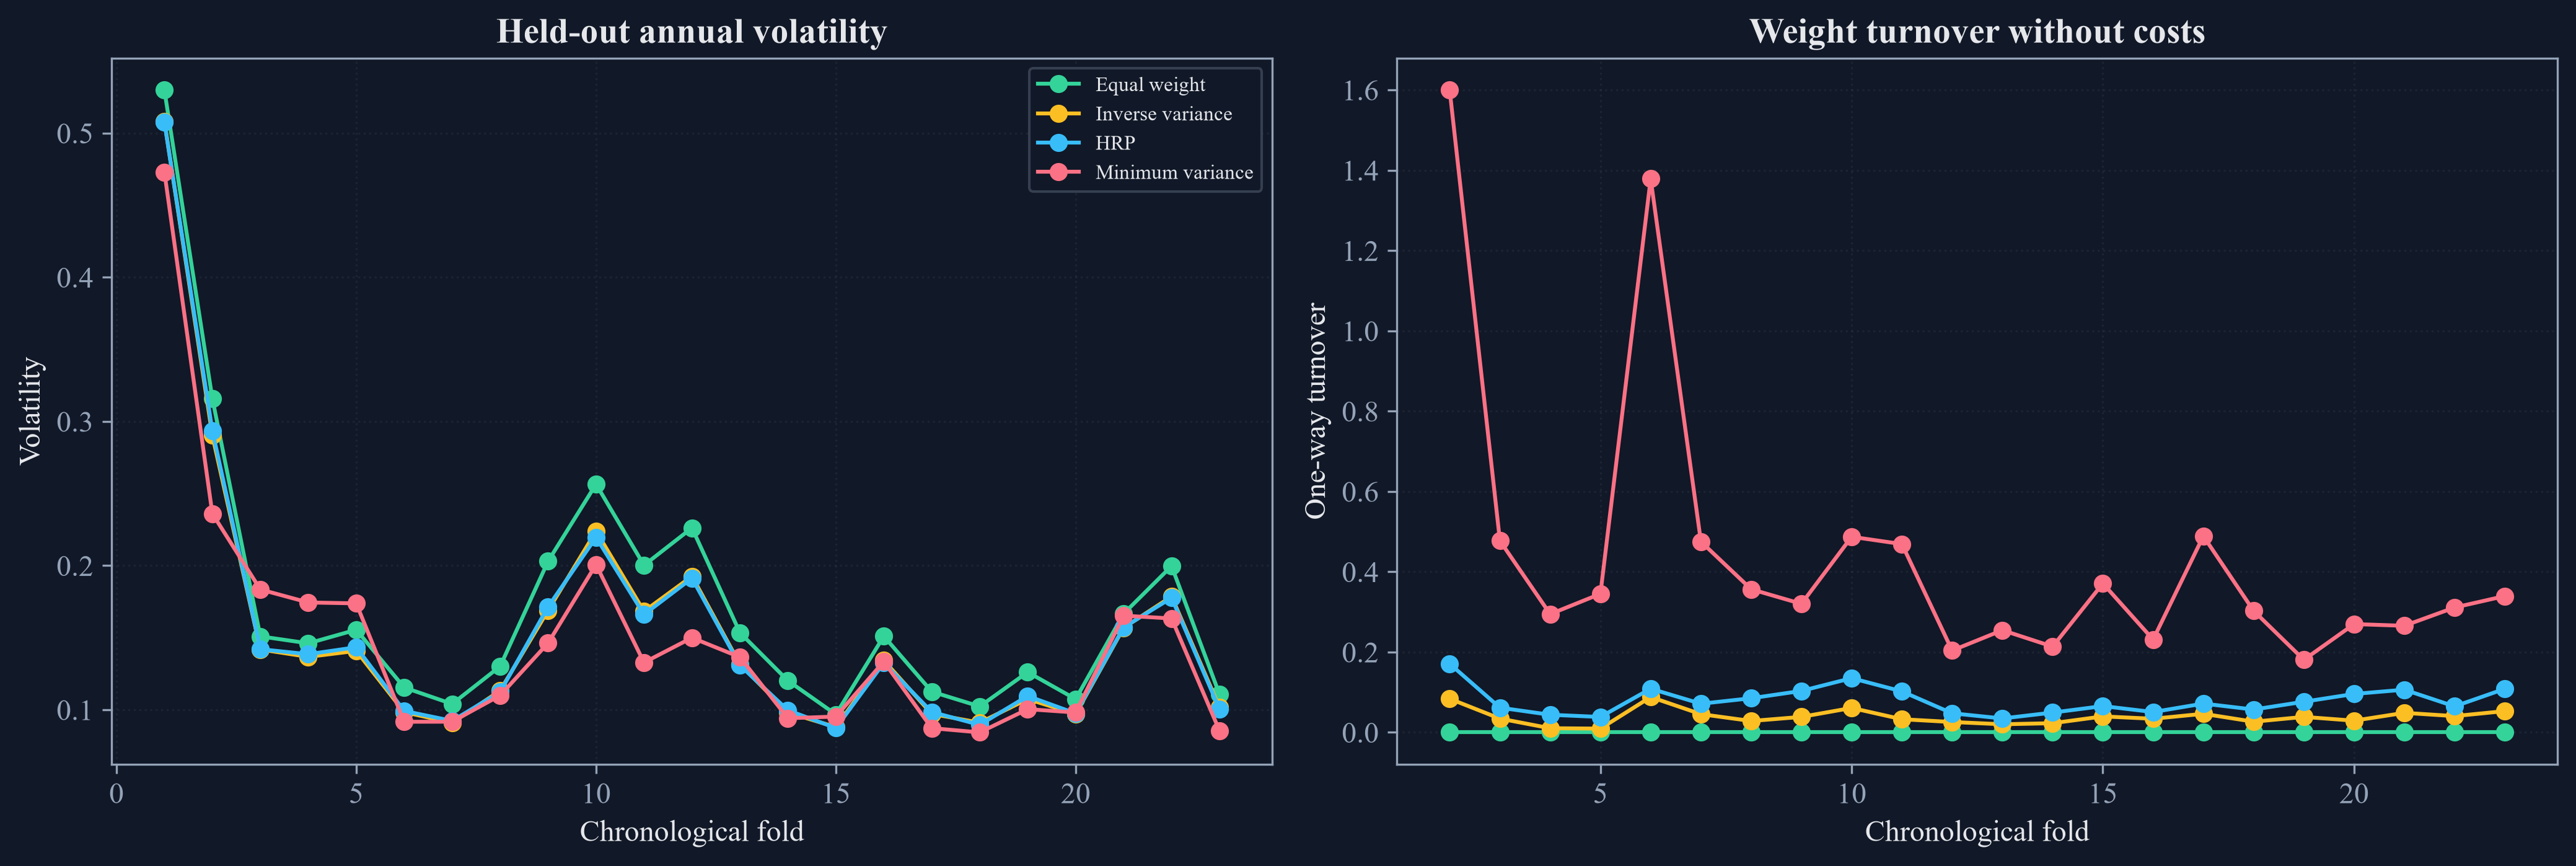

,Preliminary item,Chapter 21 location,Status
0,Public hierarchy and dendrogram,Section 21.1,Included
1,Correlation distance matrix,Section 21.1,Included
2,Quasi-diagonal ordering,Sections 21.1 and 21.2,Included
3,Recursive HRP weights,Section 21.2,Included
4,Known clustered covariance,Section 21.3,Included
5,Repeated HRP and inverse-variance comparison,Section 21.3,Included
6,Weight-stability comparison,Section 21.3,Included
7,Saved preliminary result trace,Rerun and replaced by maintained tables,Included


,Quantity,Value
0,Known-truth repetitions,60
1,Sensitivity fits,480
2,Generated turnover dates,12
3,Public rolling windows,23
4,Compared portfolio rules,4
5,Public observations,1760


In [4]:
rolling_rows = []
previous_public_weights = {}
fold = 0
for training_end in range(251, len(public_sample) - 63, 63):
    training = public_sample.iloc[training_end - 251:training_end + 1]
    testing = public_sample.iloc[training_end + 1:training_end + 64]
    covariance = training.cov() * 252.0
    correlation = training.corr()
    fitted = portfolio_set(covariance, correlation)
    fold += 1
    for method, weights in fitted.items():
        held_out = testing.to_numpy() @ weights.reindex(selected_assets).to_numpy()
        turnover_value = np.nan if method not in previous_public_weights else one_way_turnover(weights, previous_public_weights[method])
        rolling_rows.append({"Fold": fold, "Training end": str(training.index[-1].date()), "Test end": str(testing.index[-1].date()), "Method": method, "Held-out annual volatility": float(np.std(held_out, ddof=1) * np.sqrt(252.0)), "Turnover": turnover_value, "Weight concentration": float(weights @ weights), "Largest absolute weight": float(np.abs(weights).max())})
        previous_public_weights[method] = weights
public_rolling = pd.DataFrame(rolling_rows)
public_risk_summary = public_rolling.groupby("Method", as_index=False).agg(**{"Mean held-out volatility": ("Held-out annual volatility", "mean"), "Median held-out volatility": ("Held-out annual volatility", "median"), "Lowest-volatility folds": ("Held-out annual volatility", lambda values: 0), "Mean turnover": ("Turnover", "mean"), "Median concentration": ("Weight concentration", "median"), "Median largest absolute weight": ("Largest absolute weight", "median")})
winners = public_rolling.loc[public_rolling.groupby("Fold")["Held-out annual volatility"].idxmin(), ["Fold", "Method"]]
winner_counts = winners["Method"].value_counts()
public_risk_summary["Lowest-volatility folds"] = public_risk_summary["Method"].map(winner_counts).fillna(0).astype(int)
rolling_design = pd.DataFrame({"Quantity": ["Assets", "Training observations", "Held-out observations", "Windows", "Annualization factor", "Costs included"], "Value": [len(selected_assets), 252, 63, fold, 252, "No"]})
save_table(rolling_design, "public_rolling_design", "Chronological public comparison design.", "tab:chapter21-public-rolling-design")
save_table(public_risk_summary, "public_rolling_summary", "Held-out public risk, turnover, and concentration.", "tab:chapter21-public-rolling-summary")
display(rolling_design)
display(public_risk_summary)

figure, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for method, color in zip(method_order, colors):
    subset = public_rolling[public_rolling["Method"] == method]
    axes[0].plot(subset["Fold"], subset["Held-out annual volatility"], marker="o", label=method, color=color)
    axes[1].plot(subset["Fold"], subset["Turnover"], marker="o", label=method, color=color)
axes[0].set_title("Held-out annual volatility")
axes[0].set_ylabel("Volatility")
axes[1].set_title("Weight turnover without costs")
axes[1].set_ylabel("One-way turnover")
for axis in axes:
    axis.set_xlabel("Chronological fold")
    axis.grid(alpha=0.3)
axes[0].legend(fontsize=8)
figure.tight_layout()
save_figure(figure, "public_rolling_hrp_comparison")

preliminary_parity = pd.DataFrame({"Preliminary item": ["Public hierarchy and dendrogram", "Correlation distance matrix", "Quasi-diagonal ordering", "Recursive HRP weights", "Known clustered covariance", "Repeated HRP and inverse-variance comparison", "Weight-stability comparison", "Saved preliminary result trace"], "Chapter 21 location": ["Section 21.1", "Section 21.1", "Sections 21.1 and 21.2", "Section 21.2", "Section 21.3", "Section 21.3", "Section 21.3", "Rerun and replaced by maintained tables"], "Status": ["Included", "Included", "Included", "Included", "Included", "Included", "Included", "Included"]})
save_table(preliminary_parity, "preliminary_hrp_parity", "Coverage of preliminary HRP experiments.", "tab:chapter21-preliminary-parity")
display(preliminary_parity)

comparison_section_summary = pd.DataFrame({"Quantity": ["Known-truth repetitions", "Sensitivity fits", "Generated turnover dates", "Public rolling windows", "Compared portfolio rules", "Public observations"], "Value": [60, len(sensitivity_results), len(topology_turnover), fold, len(method_order), len(public_sample)]})
save_table(comparison_section_summary, "comparison_section_summary", "Section 21.3 numerical summary.", "tab:chapter21-comparison-summary")
display(comparison_section_summary)

## Tests

In [5]:
assert true_covariance.shape == (24, 24)
assert np.linalg.eigvalsh(true_covariance.to_numpy()).min() > 0.0
assert np.allclose(np.diag(true_correlation), 1.0)
assert len(repeated_results) == 60 * 4
assert repeated_results.groupby('Repetition').size().eq(4).all()
assert repeated_results['True-risk ratio'].ge(1.0 - 1e-10).all()
assert repeated_results['Allocation absolute error'].ge(0.0).all()
assert repeated_summary['Method'].nunique() == 4
assert len(paired_comparison) == 3
assert paired_comparison['Share with lower HRP risk'].between(0.0, 1.0).all()
assert len(sensitivity_results) == 2 * 3 * 2 * 20 * 2
assert sensitivity_results.groupby(['Assets', 'Training observations', 'Within correlation', 'Repetition']).size().eq(2).all()
assert sensitivity_results['True-risk ratio'].ge(1.0 - 1e-10).all()
assert len(sensitivity_summary) == 2 * 3 * 2 * 2
assert len(topology_turnover) >= 10
assert topology_turnover['Same-covariance topology gap'].ge(0.0).all()
assert topology_turnover['Estimated-tree turnover'].dropna().ge(0.0).all()
assert topology_turnover['Fixed-order turnover'].dropna().ge(0.0).all()
assert public_rolling.groupby('Fold').size().eq(4).all()
assert public_risk_summary['Lowest-volatility folds'].sum() == fold
assert public_risk_summary['Mean held-out volatility'].gt(0.0).all()
assert public_risk_summary['Mean turnover'].ge(0.0).all()
assert len(preliminary_parity) == 8
assert preliminary_parity['Status'].eq('Included').all()
assert (FIGURES / 'repeated_known_truth_portfolios.pdf').is_file()
assert (FIGURES / 'sampling_sensitivity_heatmaps.pdf').is_file()
assert (FIGURES / 'tree_turnover_diagnostics.pdf').is_file()
assert (FIGURES / 'public_rolling_hrp_comparison.pdf').is_file()
assert (TABLES / 'repeated_known_truth_summary.tex').is_file()
assert (TABLES / 'public_rolling_summary.tex').is_file()
